# DenseNet-201 missed tumors
Tumor images the model called normal (false negatives), one per row.
**Left** = Grad-CAM heatmap (where the model looked to say "normal").
**Right** = the original X-ray with its tumor annotation: **red** = tumor outline, **green** = box.
This notebook only reads the data, it never changes it.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

HEATMAPS = Path("densenet201-falsenegative-heatmaps")
IMAGES = Path("../../data/BTXRD no duplicates/images")
ANNOTATIONS = Path("../../data/BTXRD no duplicates/Annotations")

In [2]:
def draw_annotation(name):
    image = Image.open(next(IMAGES.glob(name + ".*"))).convert("RGB")  # file ends in .jpeg or .jpg
    shapes = json.loads((ANNOTATIONS / (name + ".json")).read_text())["shapes"]

    draw = ImageDraw.Draw(image)
    for shape in shapes:
        points = [tuple(p) for p in shape["points"]]
        if shape["shape_type"] == "polygon":
            draw.polygon(points, outline="red", width=8)
        else:
            (x1, y1), (x2, y2) = points
            draw.rectangle([min(x1, x2), min(y1, y2), max(x1, x2), max(y1, y2)], outline="lime", width=8)
    return image, shapes[0]["label"]

Missed tumors: 53


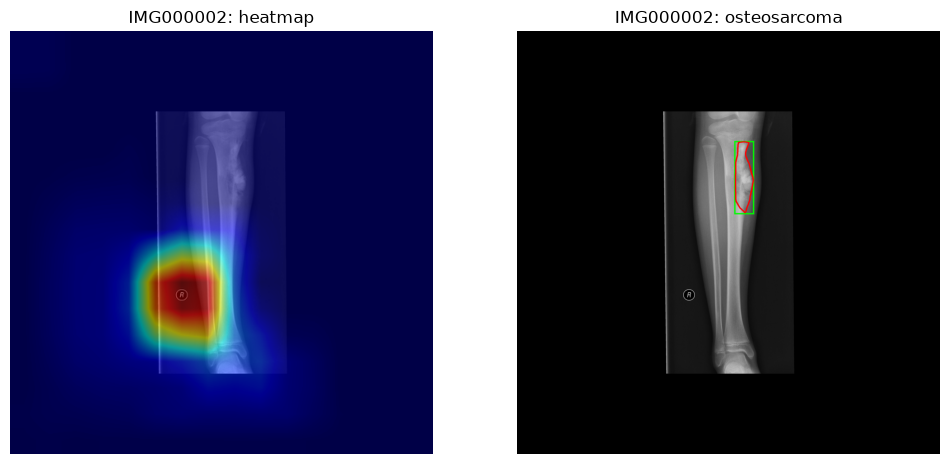

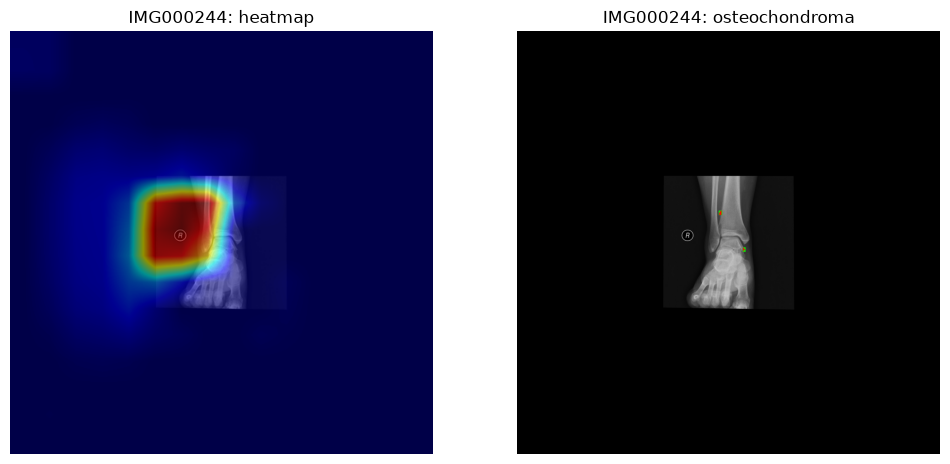

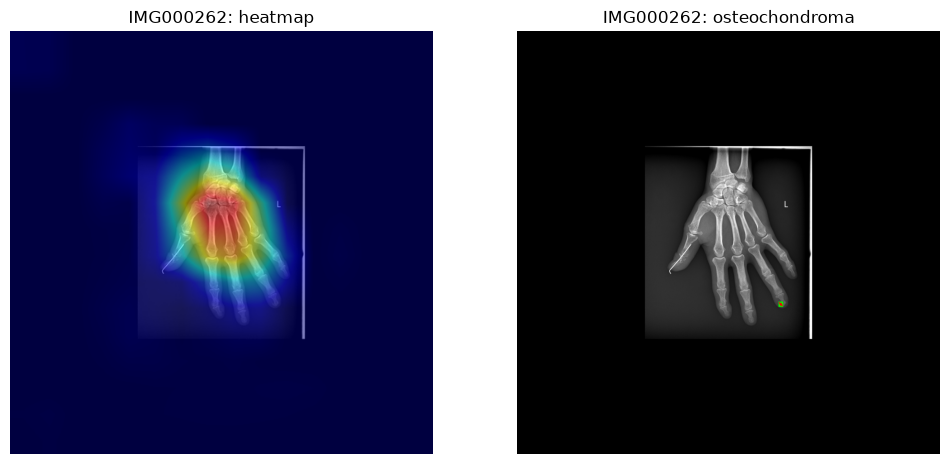

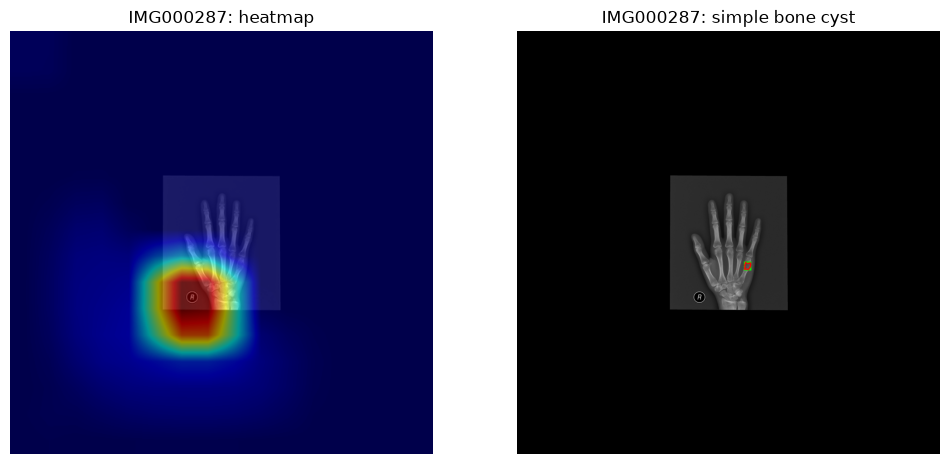

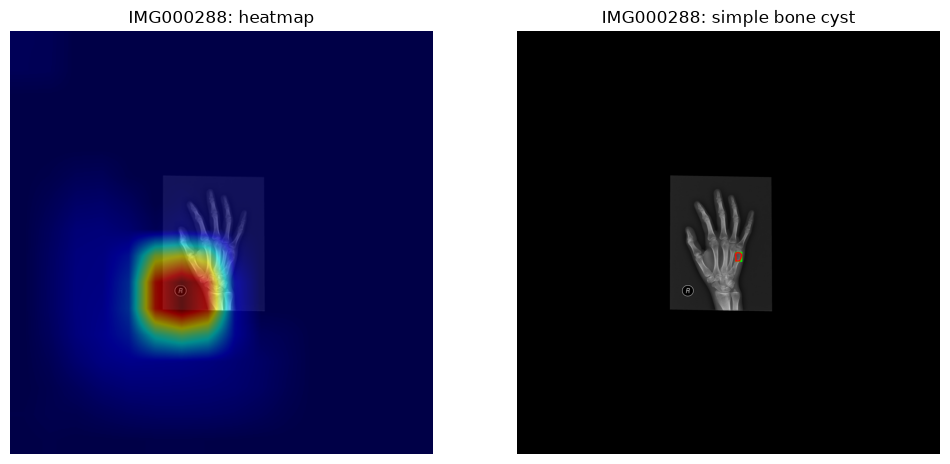

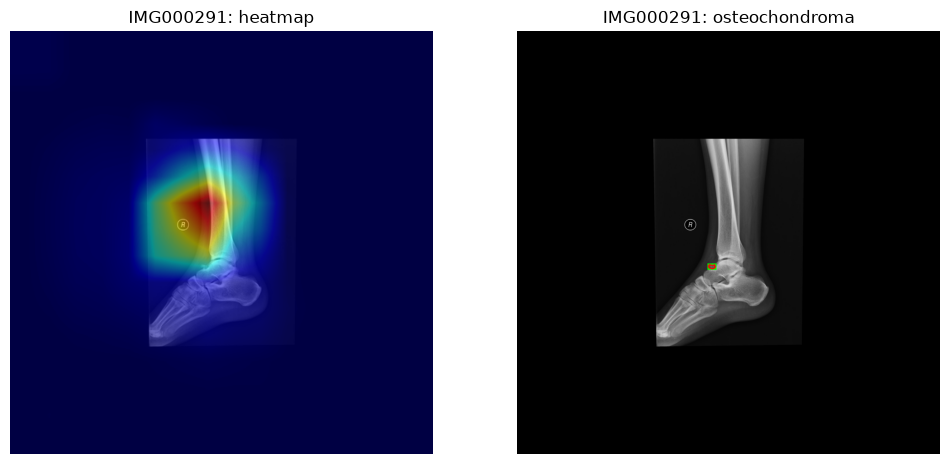

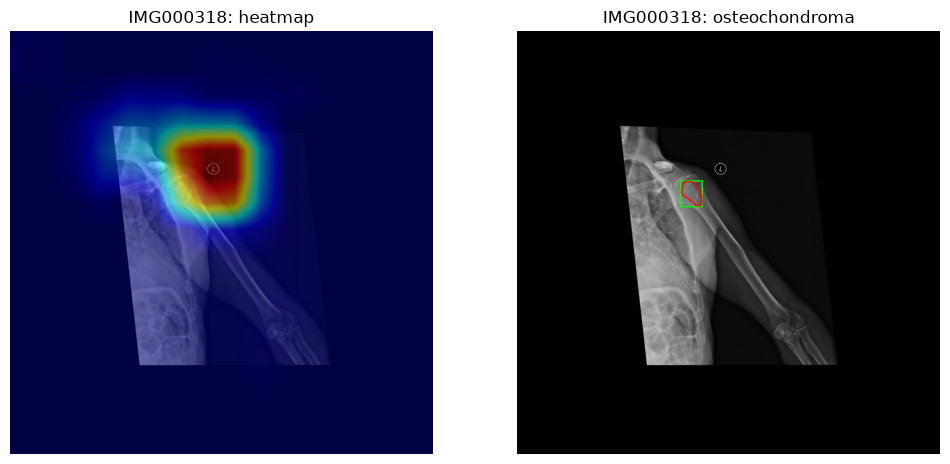

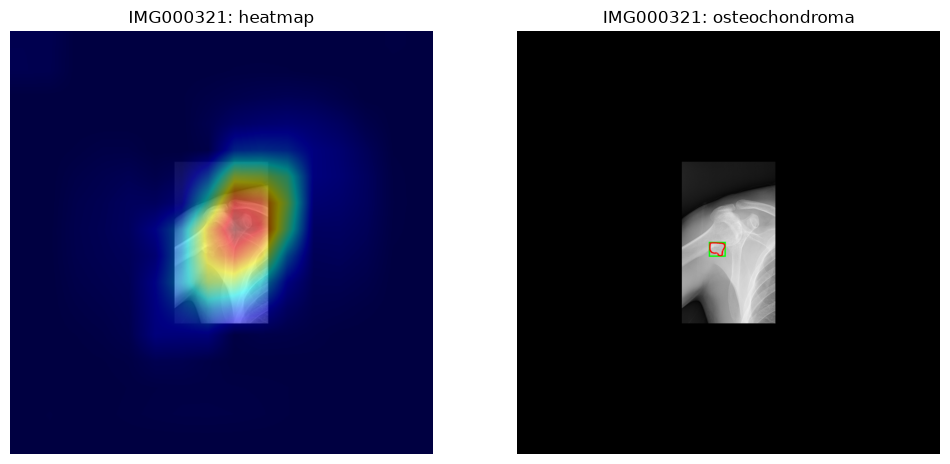

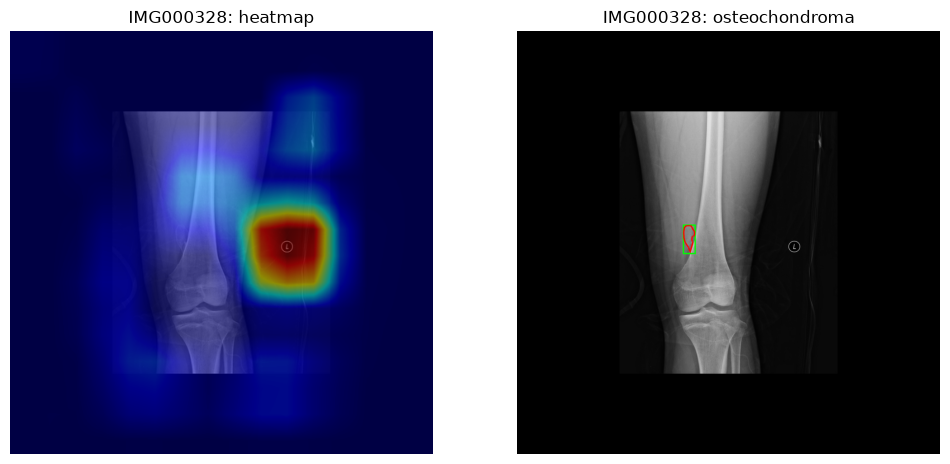

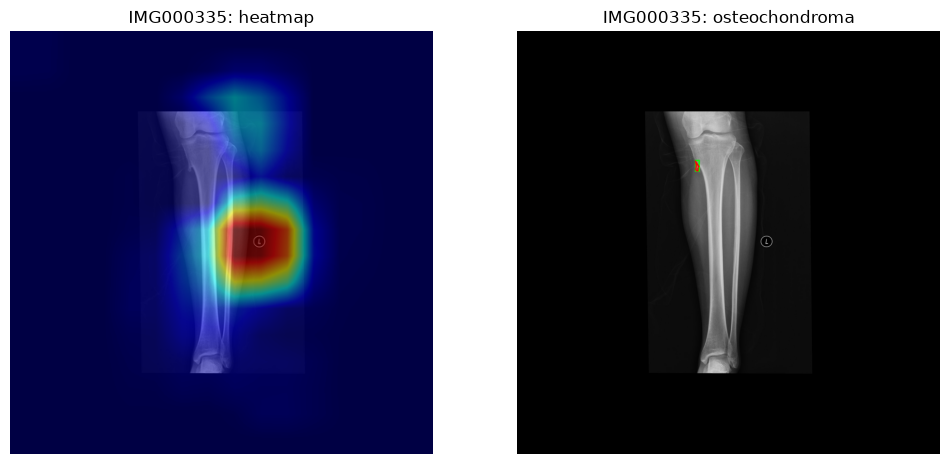

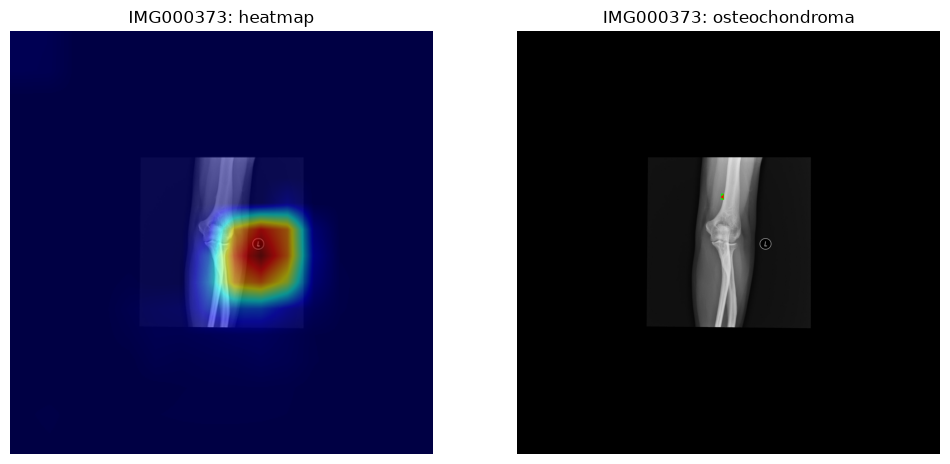

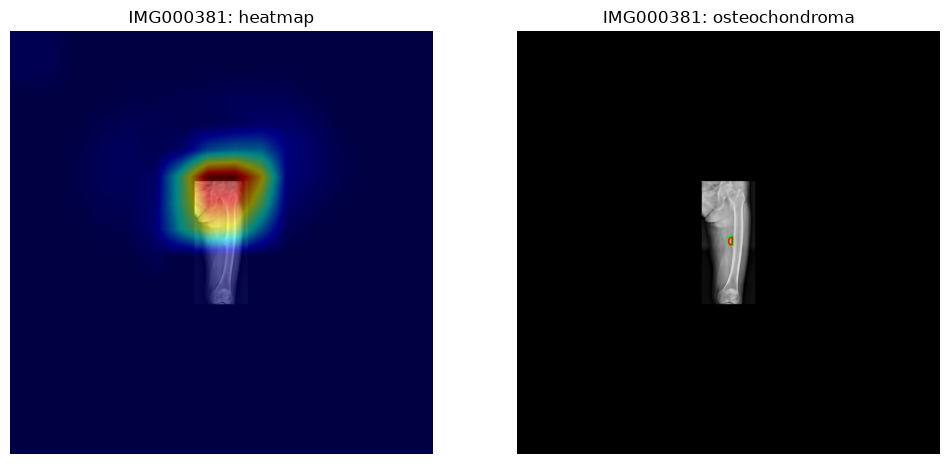

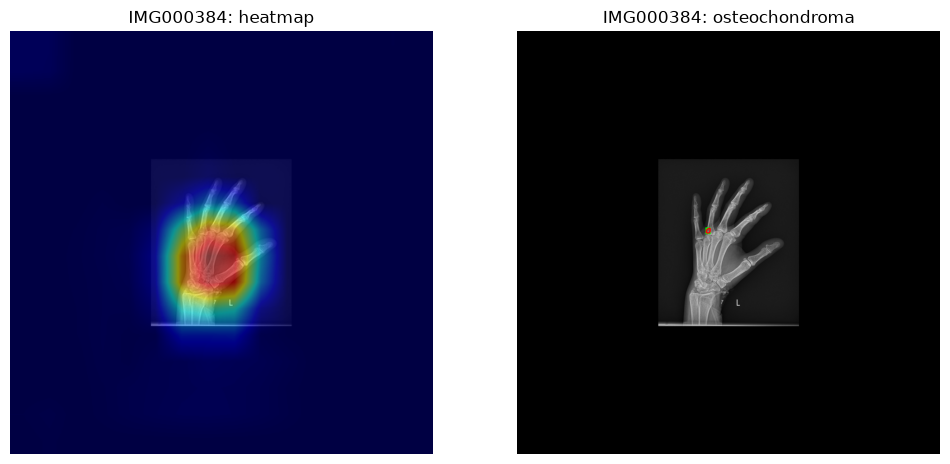

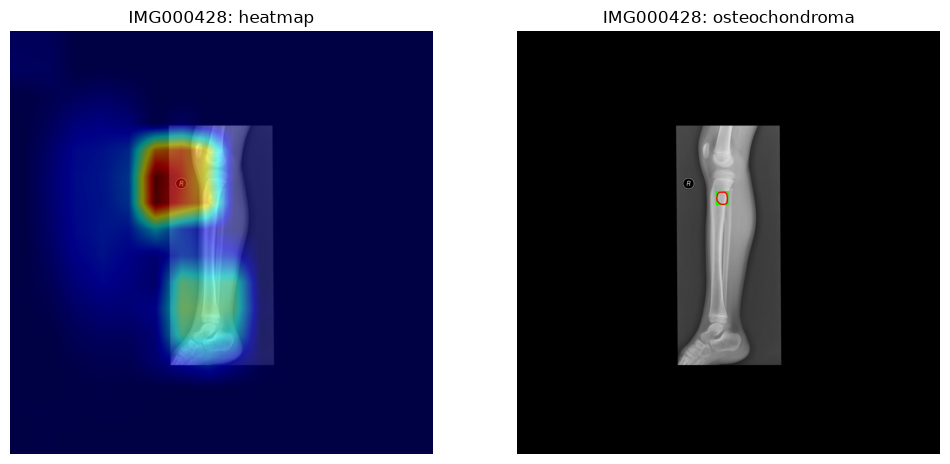

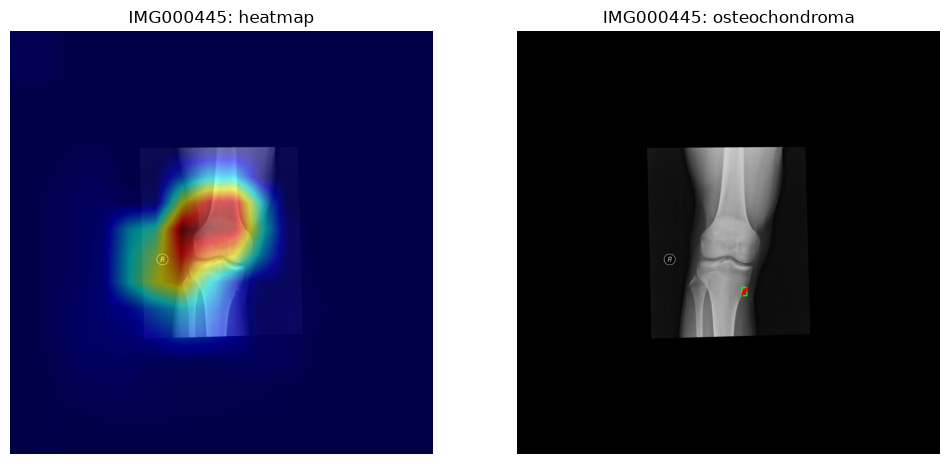

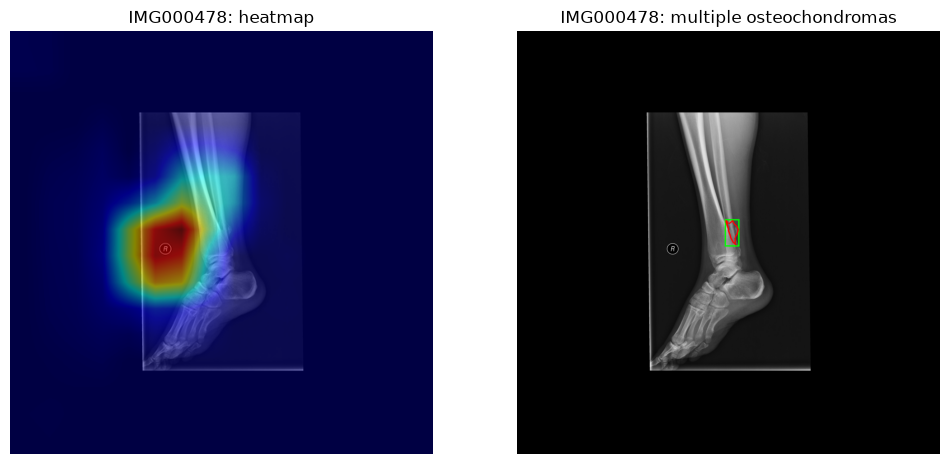

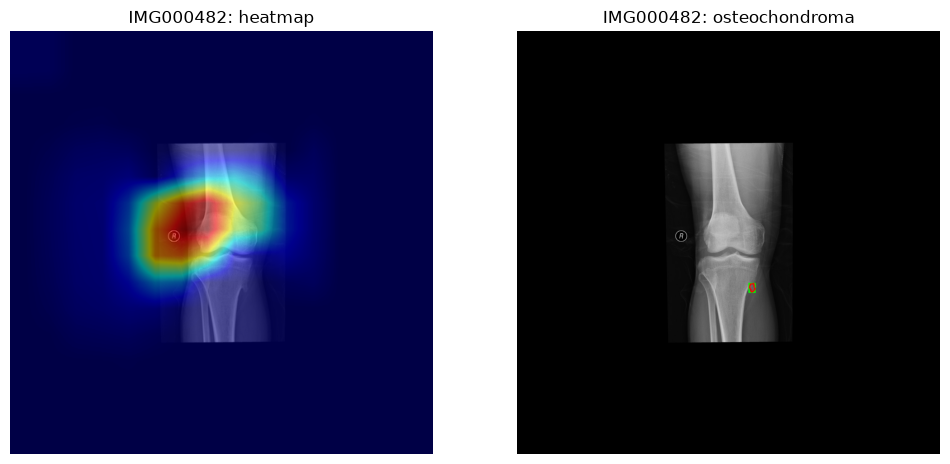

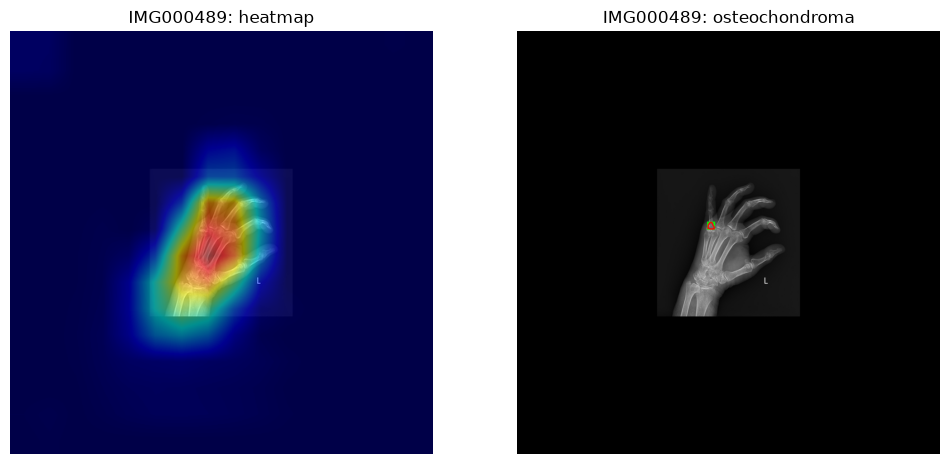

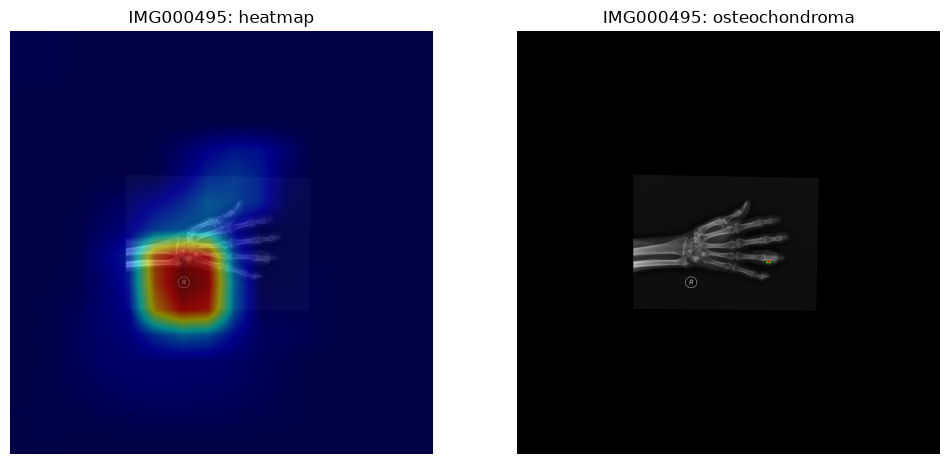

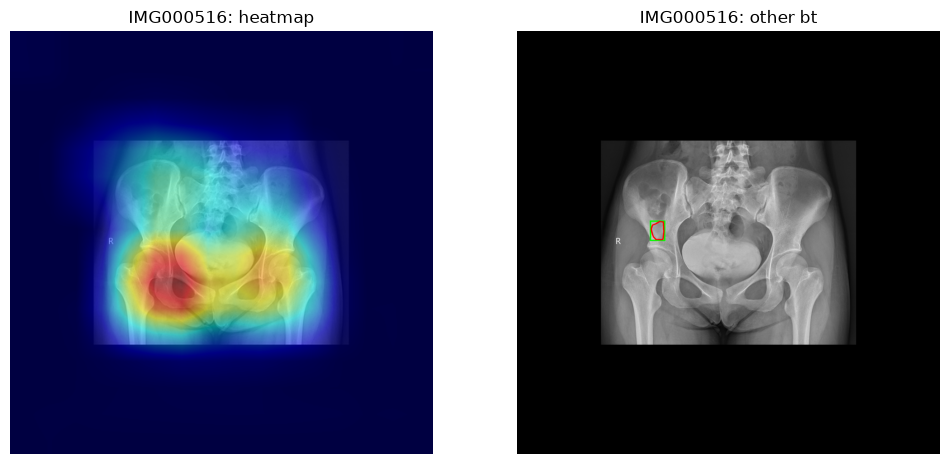

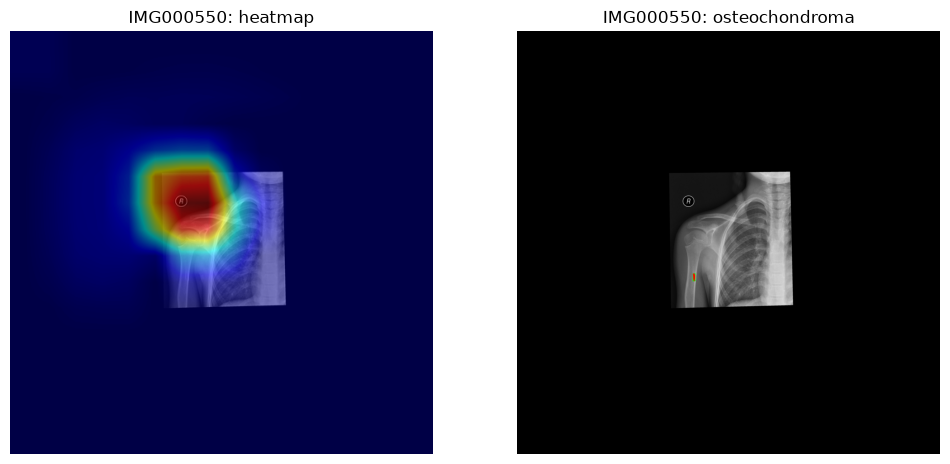

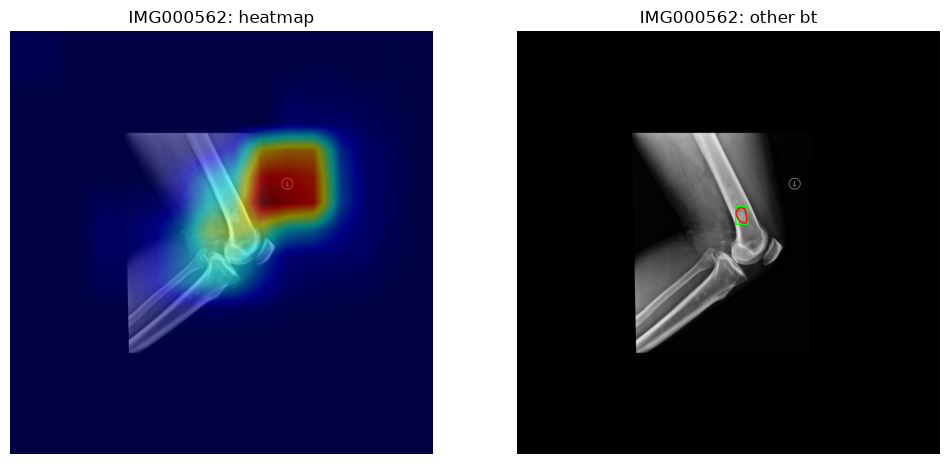

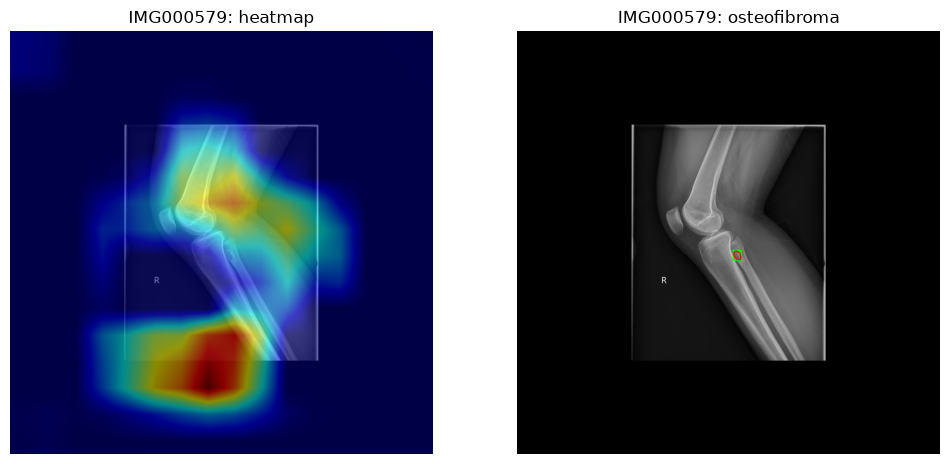

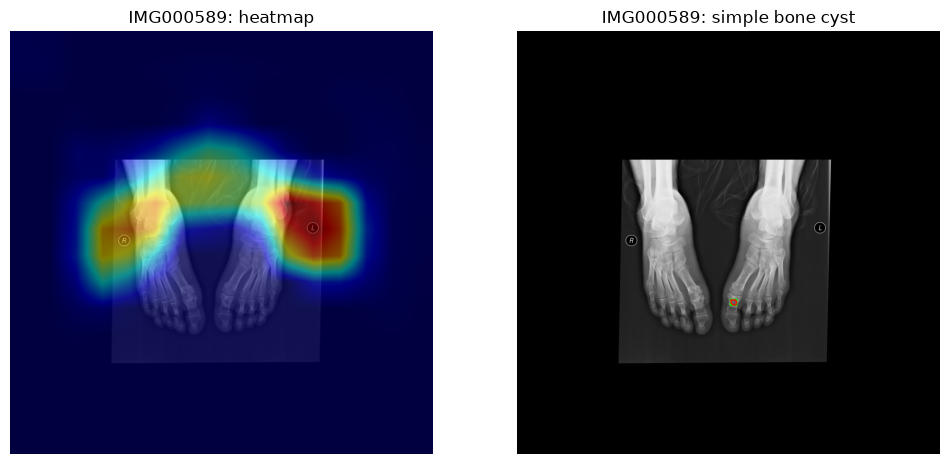

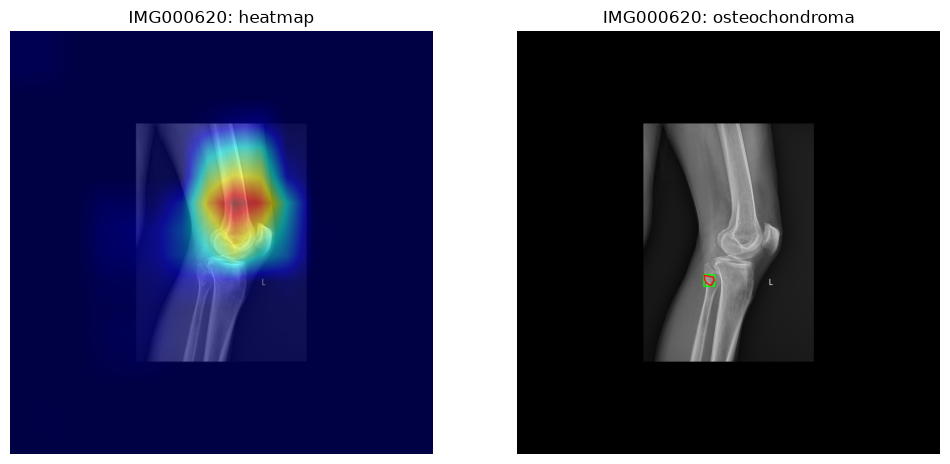

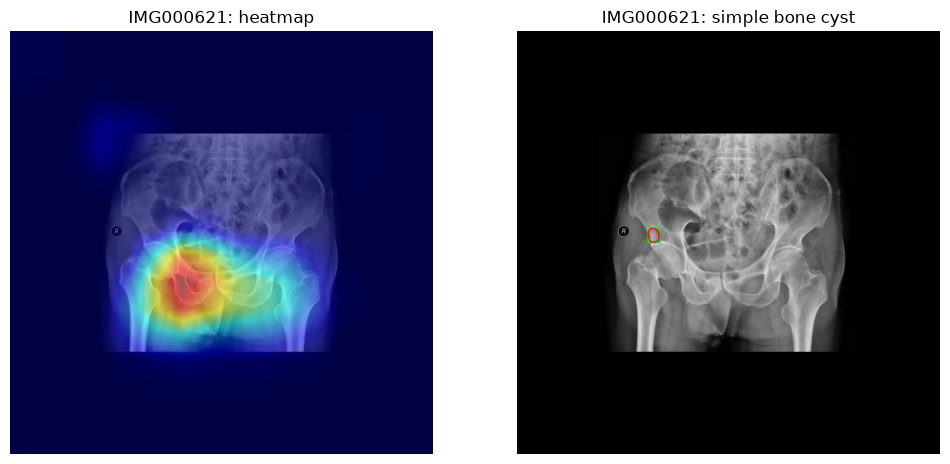

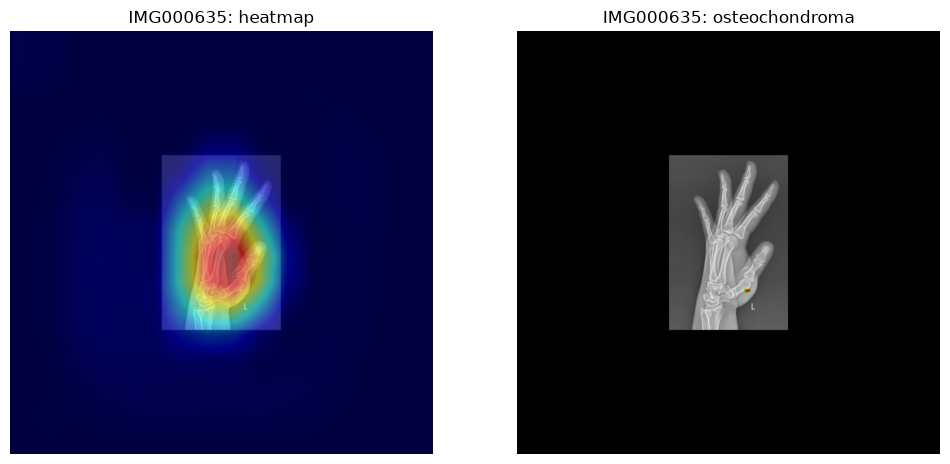

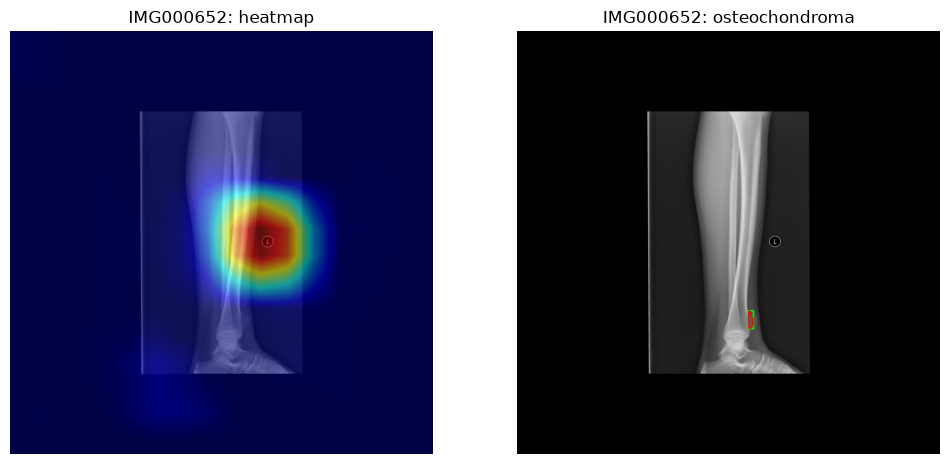

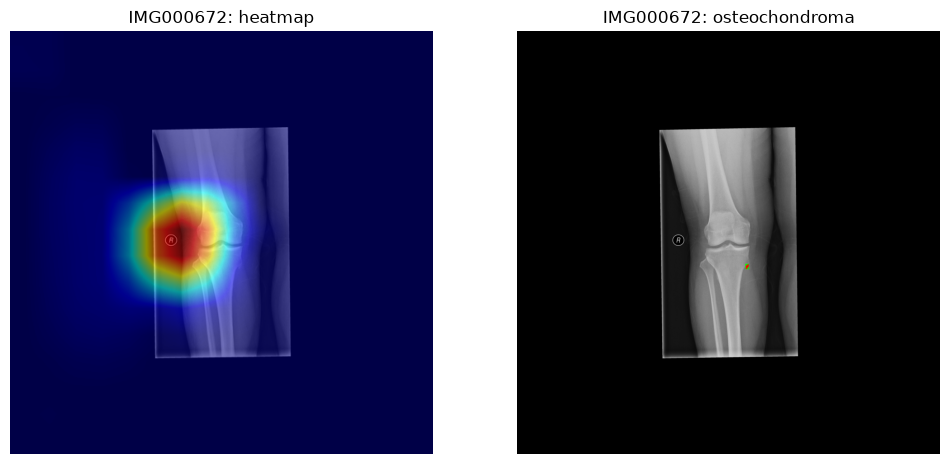

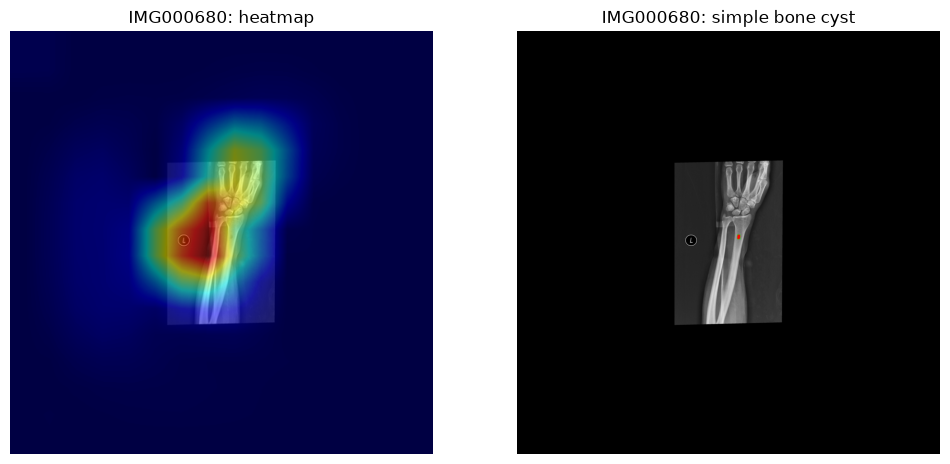

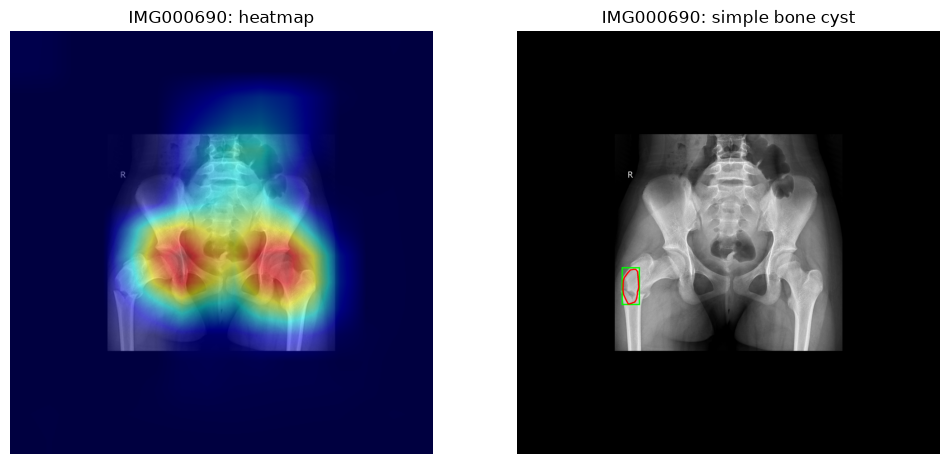

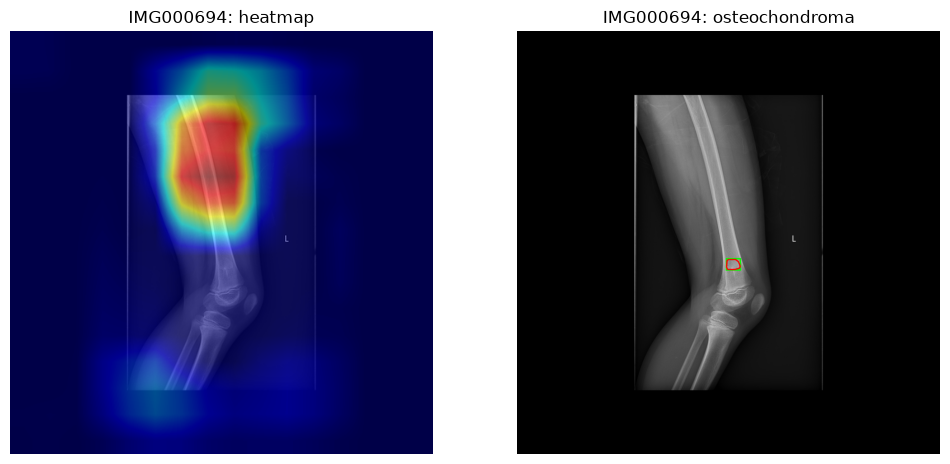

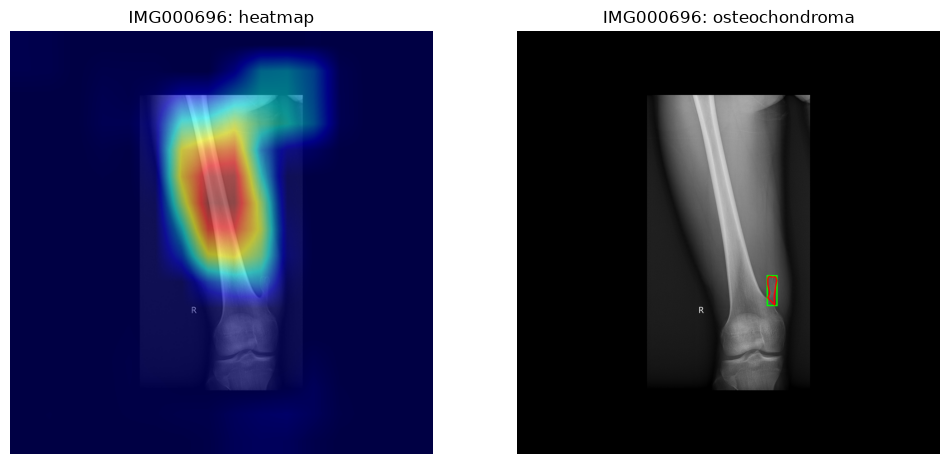

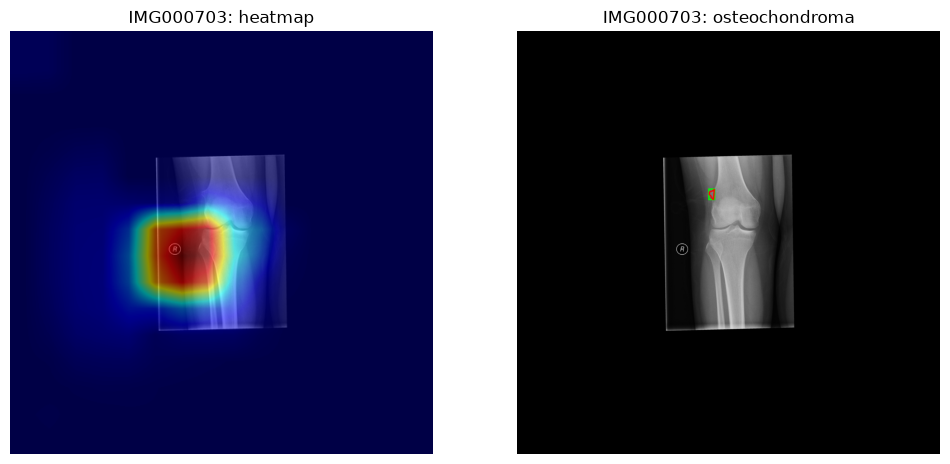

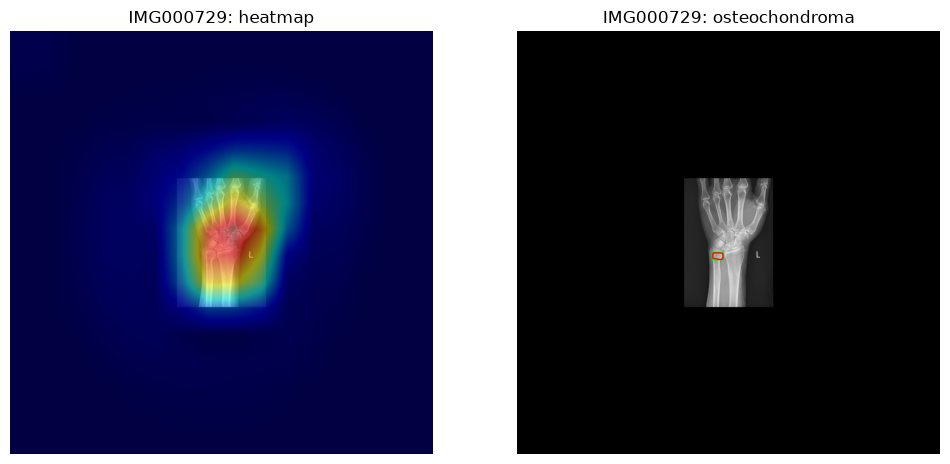

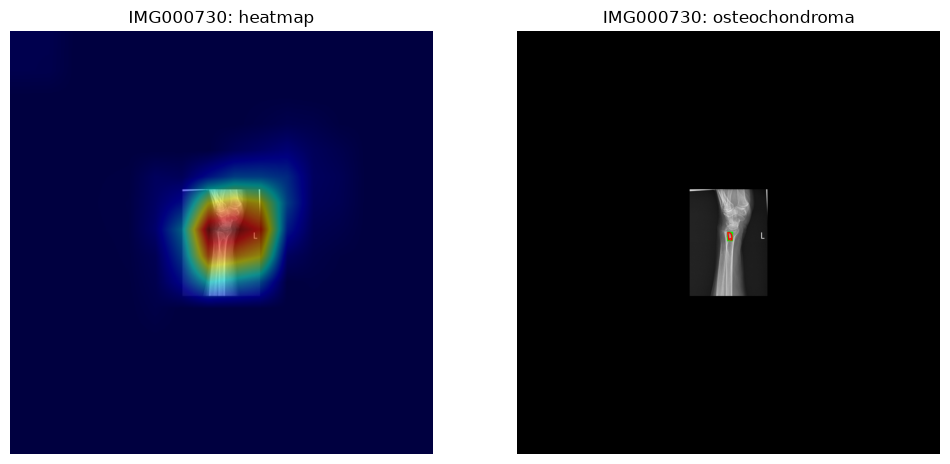

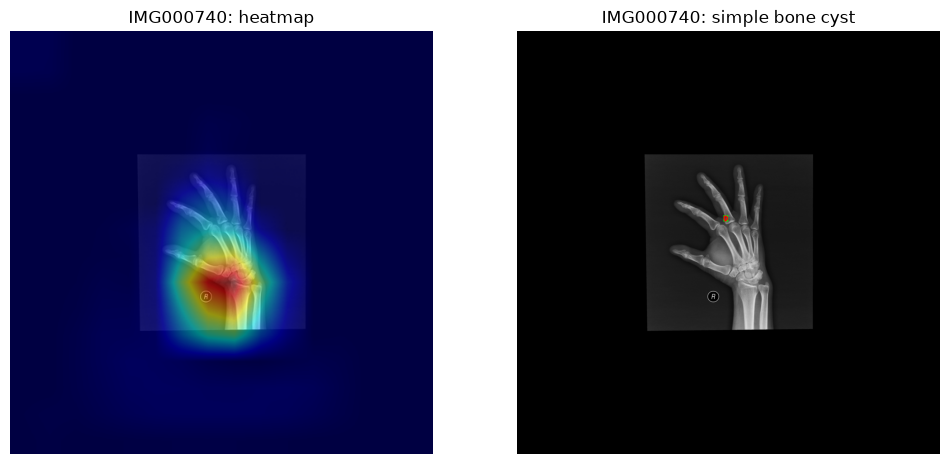

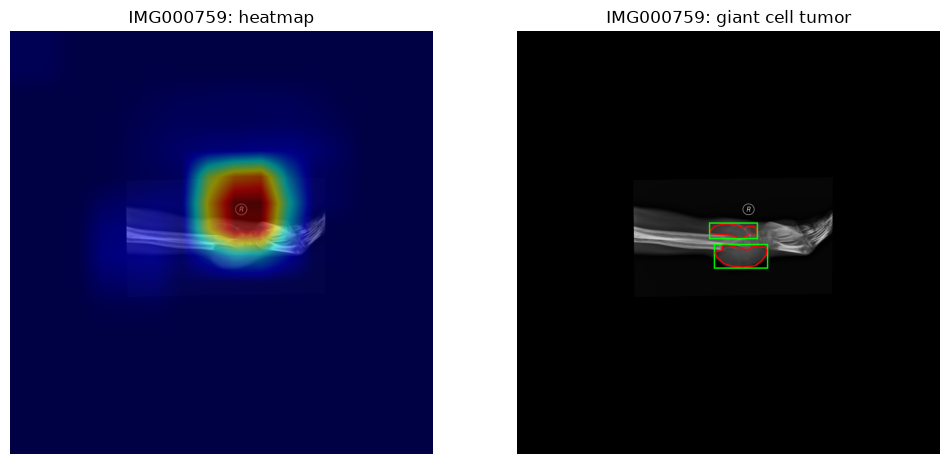

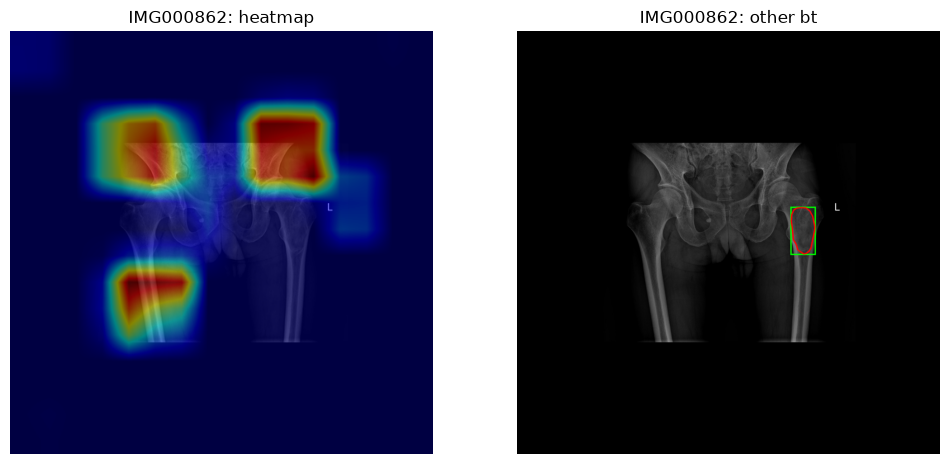

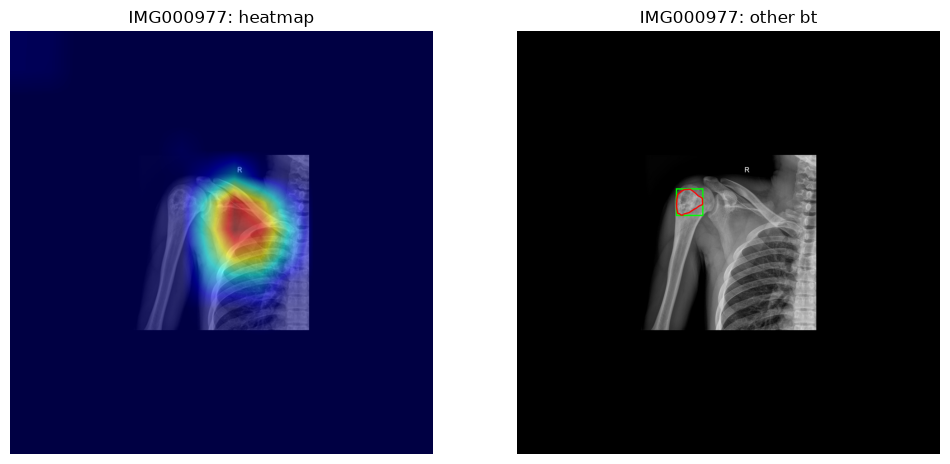

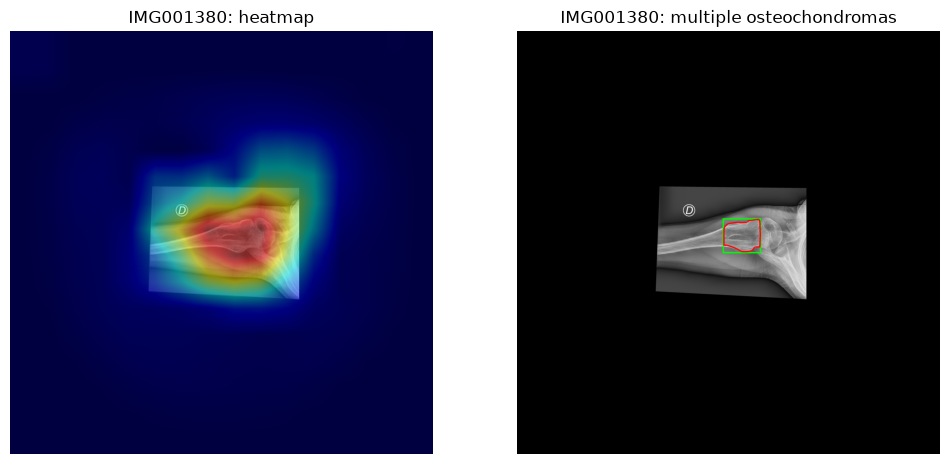

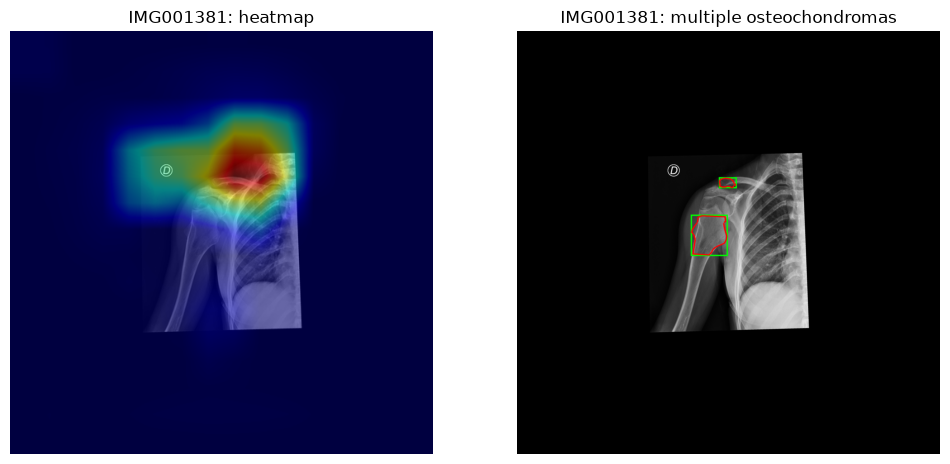

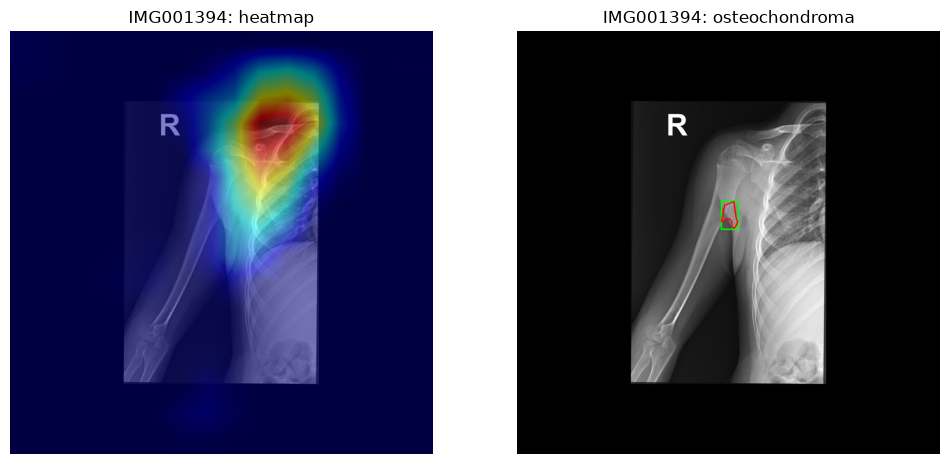

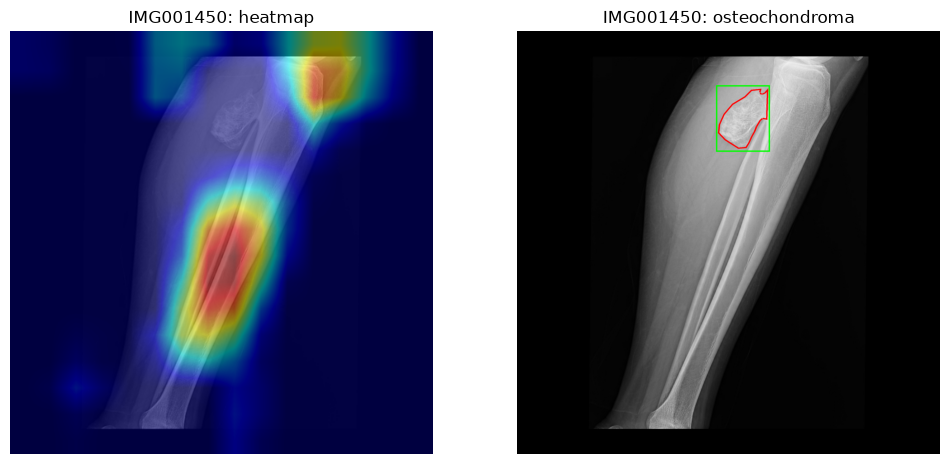

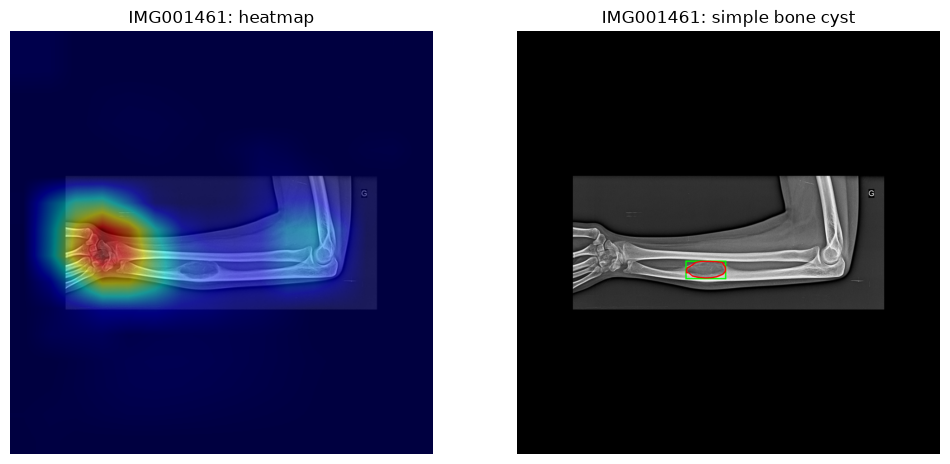

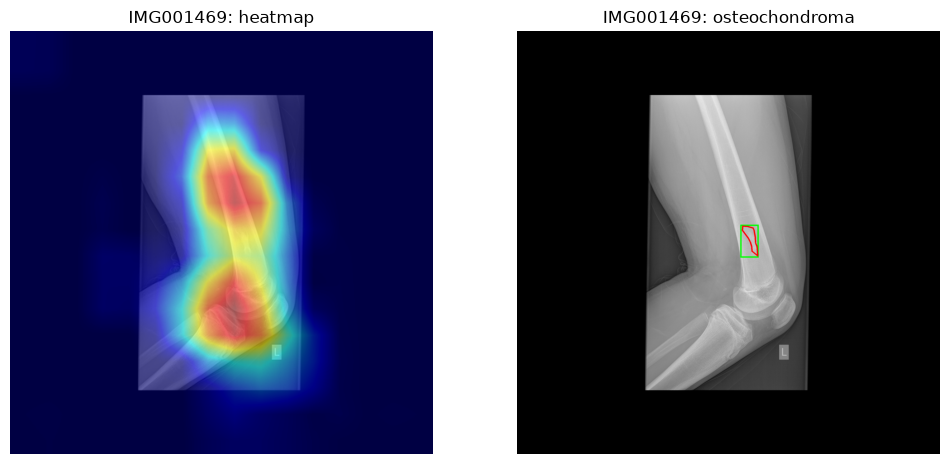

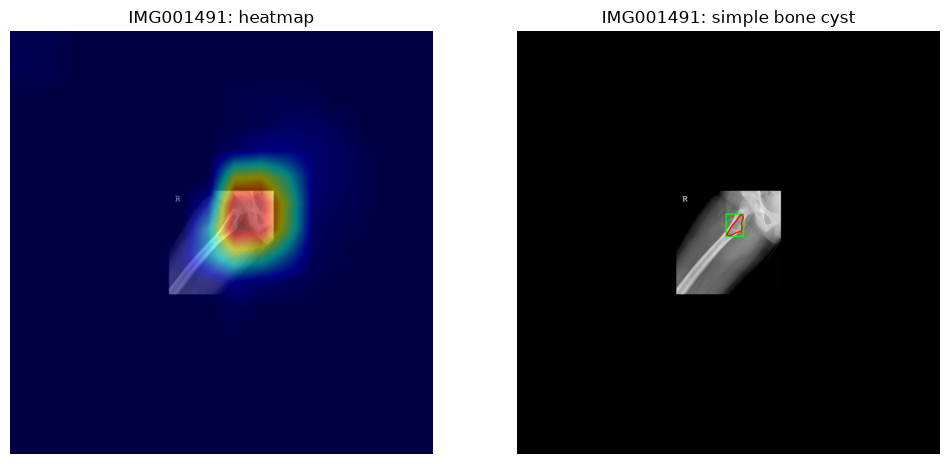

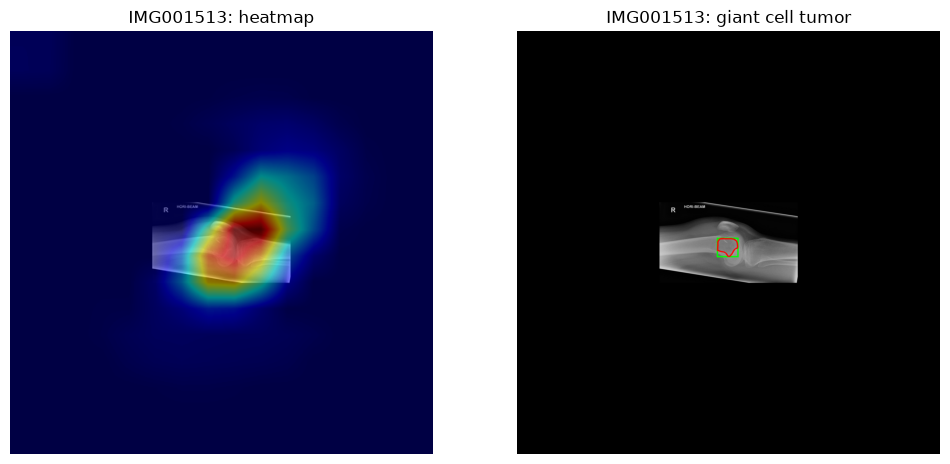

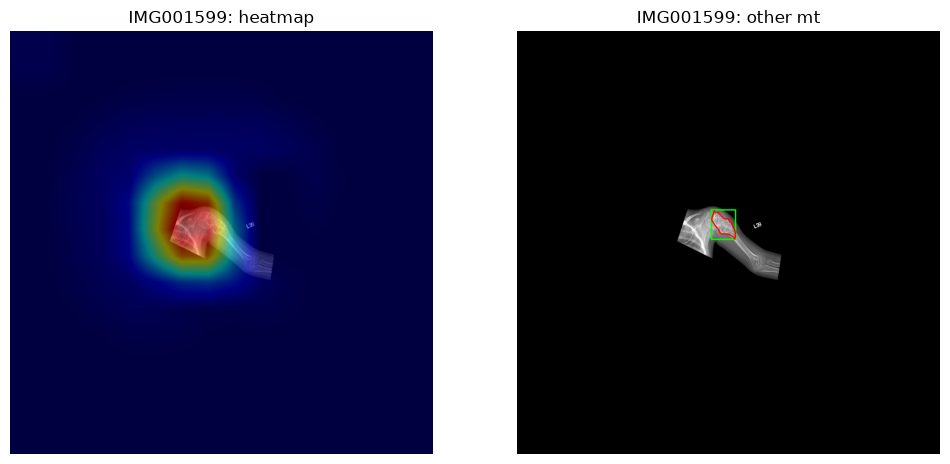

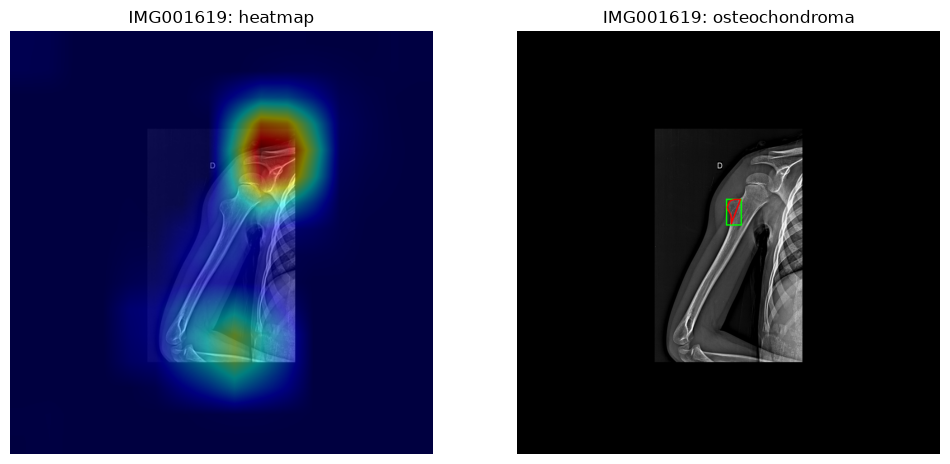

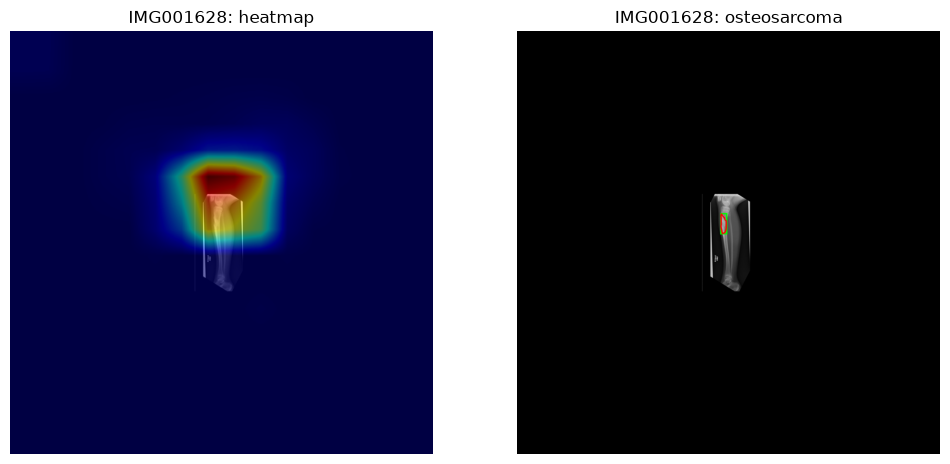

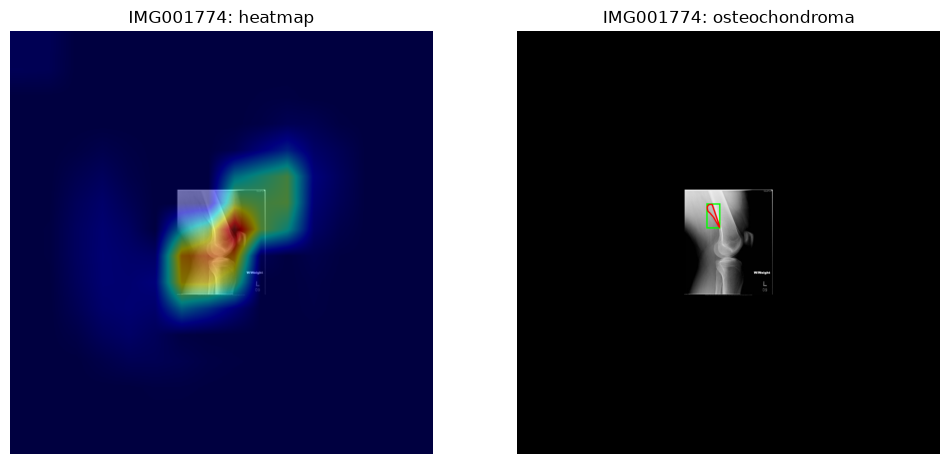

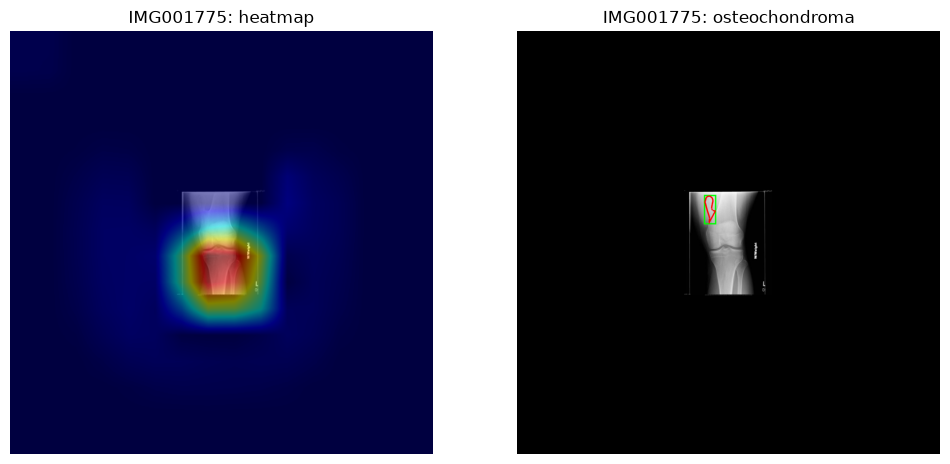

In [3]:
heatmaps = sorted(HEATMAPS.glob("*.png"))
print("Missed tumors:", len(heatmaps))

for path in heatmaps:
    name = path.stem                                 # e.g. IMG000002
    original, tumor_type = draw_annotation(name)

    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(Image.open(path))
    plt.title(f"{name}: heatmap")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(original)
    plt.title(f"{name}: {tumor_type}")
    plt.axis("off")

    plt.show()